# 01 · E1 — Online sentetik deney (makale Şekil 1, sol + orta)
**Sorumlu:** Anıl · **Plan adımları:** A2.1, A2.2, A4.2

**Problem:** $\mathcal F=[-1,1]$; $f_t(x)=1010x$ eğer $t \bmod 101 = 1$, aksi halde $-10x$. 101 adımlık döngüde toplam gradyan $+10>0$ ⇒ optimum $x^*=-1$.
**Beklenen:** Adam → $+1$ (en kötü nokta), AMSGrad → $-1$.

**Çıktılar:** `results/e1_synthetic_online/grid/*.csv`, `results/e1_synthetic_online/*.csv`, `figures/e1.*`, `figures/e1_const.*`, `figures/e1_ablation.*`

## Makaleden sapmalar
| Detay | Bizim seçimimiz | Gerekçe |
|---|---|---|
| α | {0.05, 0.1, 0.25, 0.5, 1} × {sabit α, α/√t} | Makale sentetik deneydeki α'yı vermiyor |
| Seçim kriteri | Her optimizer ve takvim için **son ortalama pişmanlık $R_T/T$ en düşük** α | Önceden belirlendi; iki optimizer'a aynı grid ve bütçe |
| İterasyon | Grid: 1M; seçilenler: 7M | Makaledeki eksen ölçeğine yakın |
| ε, bias correction | 0, yok | Makalenin analizi (Algoritma 1–2) |
| Projeksiyon | `clamp(-1, 1)` | $\mathcal F=[-1,1]$; kutu kümede ağırlıklı projeksiyon = kırpma |
| Başlangıç | $x_1 = 1$ | — |
| Seed | Yok (problem deterministik), CSV'de seed = 0 | — |
| CSV | `train_loss` = $R_t/t$; ek sütunlar `x`, `schedule` | Sentetikte test kaybı yok |
| Çizim | `common/synthetic.py` içindeki geçici yardımcılar (aynı stil) | `common/plots.py` henüz yok |

In [1]:
# --- Kurulum: repo'yu çek, yolları ayarla (00_tests ile aynı) ---
import os, sys, subprocess
REPO = "https://github.com/ybilgici/DeepLearning_Proje.git"
if os.path.exists("/kaggle"):
    ROOT = "/kaggle/working/DeepLearning_Proje"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", REPO, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
else:  # lokal çalıştırma: notebooks/ klasörünün bir üstü repo kökü
    ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import math
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from optim import paper_adam_step, init_state                     # Yiğit — ortak optimizer
from common.synthetic import (simulate, write_csv, online_grad, PeriodicGrad, StochasticGrad,
                              STYLE, style, band, save_fig)

QUICK = os.environ.get("QUICK", "0") == "1"   # True → kısa test koşusu (adım sayıları küçülür)
FIG = os.path.join(ROOT, "figures")
print("torch", torch.__version__, "| QUICK =", QUICK, "| commit:",
      subprocess.run(["git", "-C", ROOT, "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip())

torch 2.15.0+cu132 | QUICK = False | commit: d0b821c


## 1. Grid — tüm konfigürasyonlar tek tensörde, 1M adım (A2.1)

In [2]:
ALPHAS = [0.05, 0.1, 0.25, 0.5, 1.0]
T_GRID = 50_000 if QUICK else 1_000_000
cfg_grid = pd.DataFrame([dict(optimizer=o, lr=a, schedule=s, beta1=0.9, beta2=0.99, seed=0)
                         for o in ("adam", "amsgrad") for a in ALPHAS for s in ("sqrt", "const")])
print(f"{len(cfg_grid)} koşu × {T_GRID:,} adım")
out_grid = simulate(cfg_grid, T_GRID, online_grad, x_star=-1.0, log_every=1000)
print(f"süre: {out_grid['seconds']:.0f} s")
write_csv("e1_grid", cfg_grid, out_grid, os.path.join(ROOT, "results/e1_synthetic_online/grid"))
summary = cfg_grid.assign(final_x=out_grid["x_final"], final_avg_regret=out_grid["avg_regret_final"])
summary

20 koşu × 1,000,000 adım


  t=    100,000  (  16.8 s)


  t=    200,000  (  33.8 s)


  t=    300,000  (  51.2 s)


  t=    400,000  (  68.2 s)


  t=    500,000  (  85.6 s)


... (2 outputs left out)

  t=    800,000  ( 134.1 s)


  t=    900,000  ( 151.0 s)


  t=  1,000,000  ( 165.9 s)
süre: 166 s


,optimizer,lr,schedule,beta1,beta2,seed,final_x,final_avg_regret
0,adam,0.05,sqrt,0.9,0.99,0,1.000000,0.201134
1,adam,0.05,const,0.9,0.99,0,1.000000,1.697785
2,adam,0.10,sqrt,0.9,0.99,0,1.000000,0.204228
3,adam,0.10,const,0.9,0.99,0,1.000000,3.197531
4,adam,0.25,sqrt,0.9,0.99,0,1.000000,0.213511
5,adam,0.25,const,0.9,0.99,0,1.000000,7.696766
6,adam,0.50,sqrt,0.9,0.99,0,1.000000,0.228981
7,adam,0.50,const,0.9,0.99,0,1.000000,9.711842
8,adam,1.00,sqrt,0.9,0.99,0,1.000000,0.259127
9,adam,1.00,const,0.9,0.99,0,1.000000,7.971544


### Seçim (kriter önceden belirlendi: son $R_T/T$ en düşük)

In [3]:
best = summary.loc[summary.groupby(["optimizer", "schedule"])["final_avg_regret"].idxmin()].reset_index(drop=True)
best

,optimizer,lr,schedule,beta1,beta2,seed,final_x,final_avg_regret
0,adam,0.05,const,0.9,0.99,0,1.000000,1.697785
1,adam,0.05,sqrt,0.9,0.99,0,1.000000,0.201134
2,amsgrad,0.05,const,0.9,0.99,0,-0.732164,1.651846
3,amsgrad,0.50,sqrt,0.9,0.99,0,-0.997322,0.036160


## 2. Seçilenler — 7M adım (A2.1)

In [4]:
T_LONG = 100_000 if QUICK else 7_000_000
cfg = best[["optimizer", "lr", "schedule", "beta1", "beta2", "seed"]]
out = simulate(cfg, T_LONG, online_grad, x_star=-1.0, log_every=1000)
print(f"süre: {out['seconds']:.0f} s")
write_csv("e1", cfg, out, os.path.join(ROOT, "results/e1_synthetic_online"))
cfg.assign(final_x=out["x_final"], final_avg_regret=out["avg_regret_final"])

  t=    700,000  ( 105.2 s)


  t=  1,400,000  ( 209.6 s)


  t=  2,100,000  ( 314.7 s)


  t=  2,800,000  ( 418.8 s)


  t=  3,500,000  ( 518.5 s)


  t=  4,200,000  ( 594.1 s)


  t=  4,900,000  ( 663.2 s)


  t=  5,600,000  ( 734.1 s)


  t=  6,300,000  ( 806.8 s)


  t=  7,000,000  ( 878.8 s)
süre: 879 s


,optimizer,lr,schedule,beta1,beta2,seed,final_x,final_avg_regret
0,adam,0.05,const,0.9,0.99,0,1.000000,1.697706
1,adam,0.05,sqrt,0.9,0.99,0,1.000000,0.199187
2,amsgrad,0.05,const,0.9,0.99,0,-0.755801,1.647509
3,amsgrad,0.50,sqrt,0.9,0.99,0,-0.999077,0.012909


## 3. Şekil 1 kopyası (A2.2)

kaydedildi: /home/claude/DeepLearning_Proje/figures/e1.png / .pdf


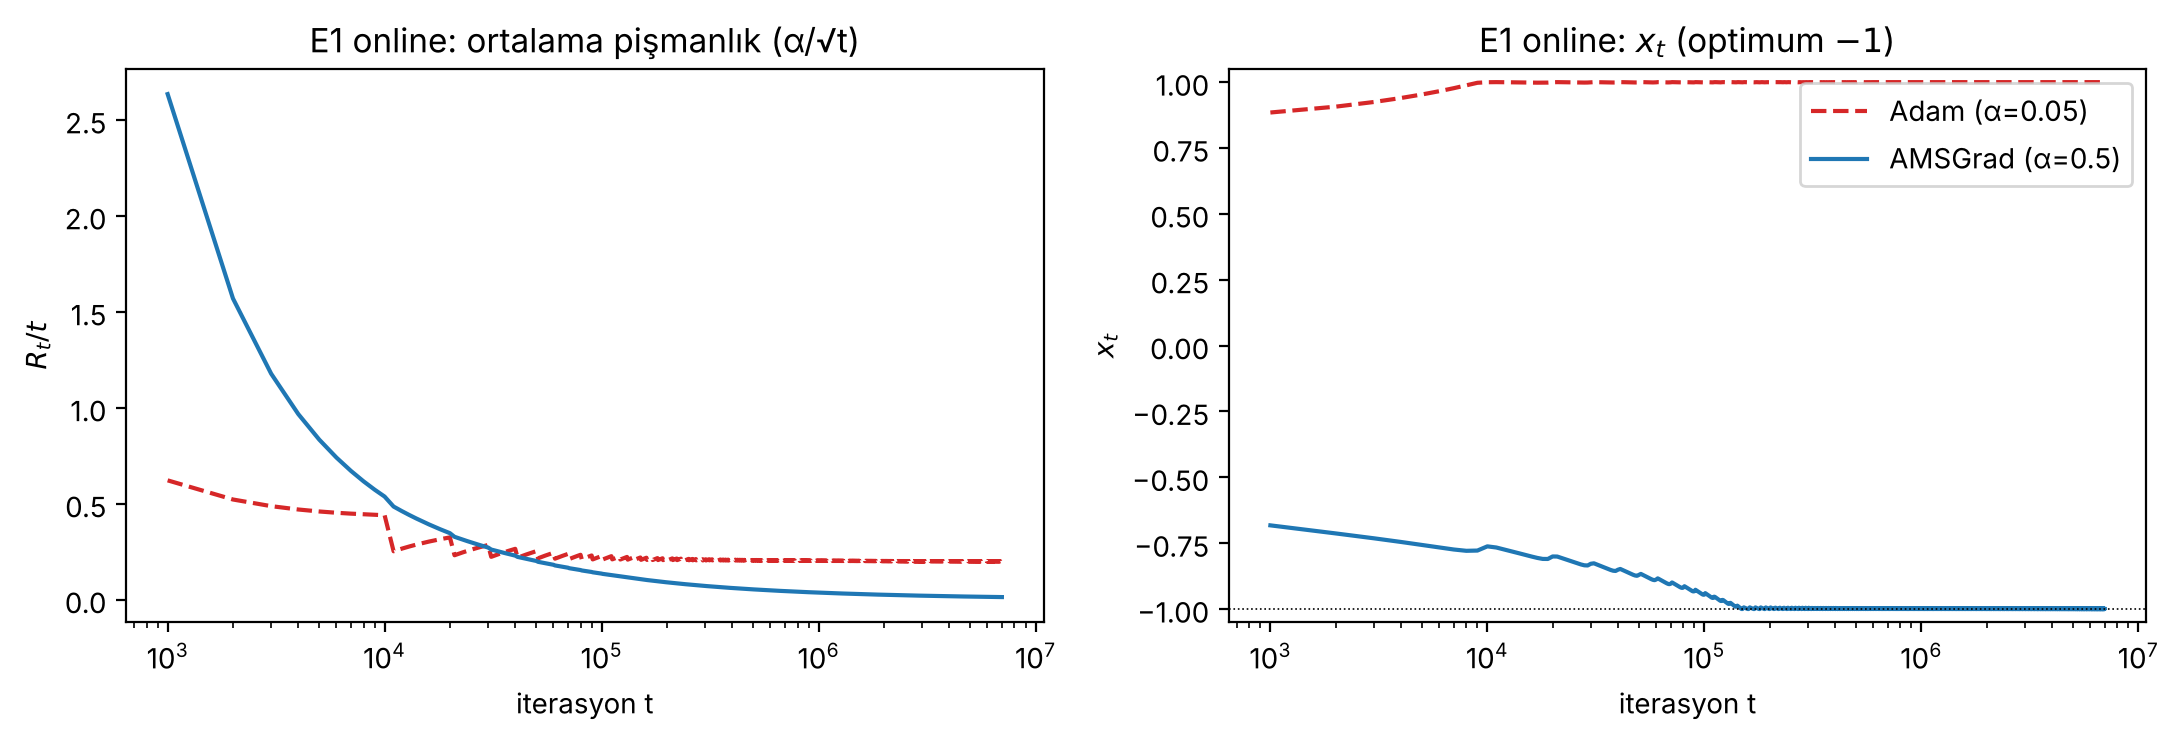

kaydedildi: /home/claude/DeepLearning_Proje/figures/e1_const.png / .pdf


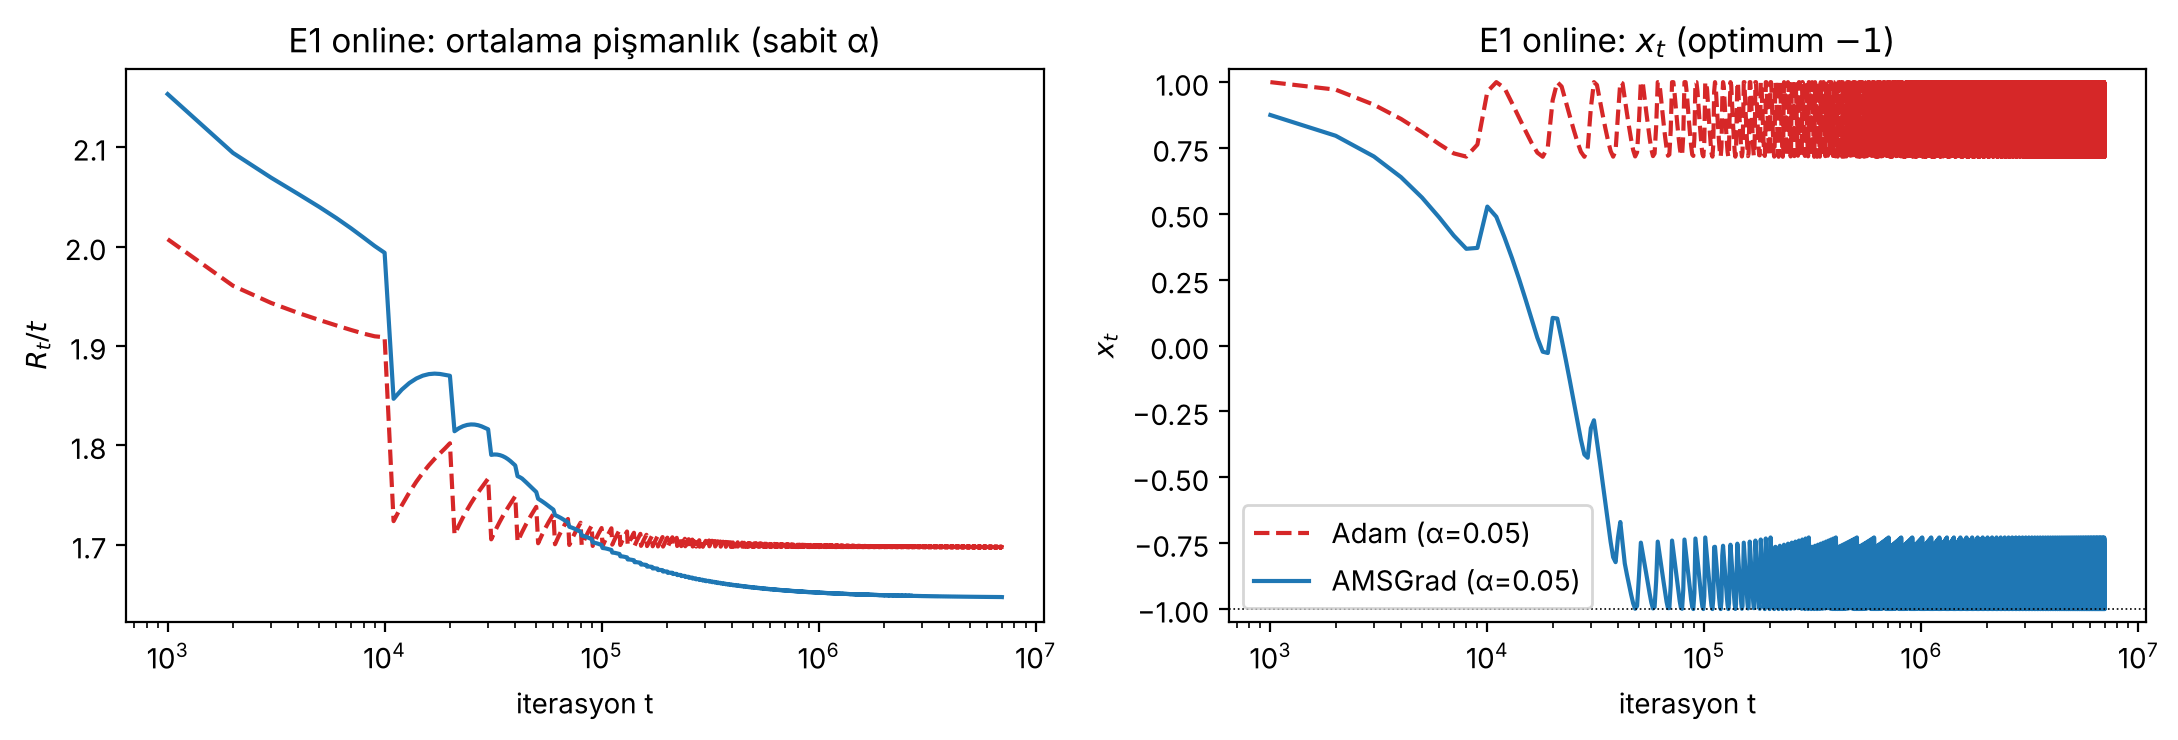

Adam son R_t/t = 0.1992  (x = +1'de oturan algoritma için teorik değer 20/101 = 0.1980)


In [5]:
def e1_figure(sched, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for i, r in cfg.iterrows():
        if r["schedule"] != sched:
            continue
        s = style(r["optimizer"], label=f"{STYLE[r['optimizer']]['label']} (α={r['lr']})")
        ax[0].plot(out["steps"], out["avg_regret"][:, i], **s)
        ax[1].plot(out["steps"], out["x"][:, i], **s)
    tak = "α/√t" if sched == "sqrt" else "sabit α"
    ax[0].set(xscale="log", xlabel="iterasyon t", ylabel="$R_t/t$", title=f"E1 online: ortalama pişmanlık ({tak})")
    ax[1].set(xscale="log", xlabel="iterasyon t", ylabel="$x_t$", ylim=(-1.05, 1.05), title="E1 online: $x_t$ (optimum $-1$)")
    ax[1].axhline(-1, color="k", lw=0.6, ls=":"); ax[1].legend()
    fig.tight_layout(); save_fig(fig, name, FIG); plt.show()

e1_figure("sqrt", "e1")
e1_figure("const", "e1_const")

i_adam = cfg.index[(cfg.optimizer == "adam") & (cfg.schedule == "sqrt")][0]
print(f"Adam son R_t/t = {out['avg_regret_final'][i_adam]:.4f}  "
      f"(x = +1'de oturan algoritma için teorik değer 20/101 = {20/101:.4f})")

## 4. Ablation (A4.2): bias correction + ε sonucu değiştiriyor mu?
- **Makale:** `bias_correction=False, eps=0`
- **PyTorch formülü:** `bias_correction=True, eps=1e-8` (Yiğit'in testinde `torch.optim.Adam` ile birebir aynı olduğu gösterildi) — vektörize, tam uzunluk
- **Kontrol:** gerçek `torch.optim.Adam(amsgrad=True)`, kısa koşu

kaydedildi: /home/claude/DeepLearning_Proje/figures/e1_ablation.png / .pdf


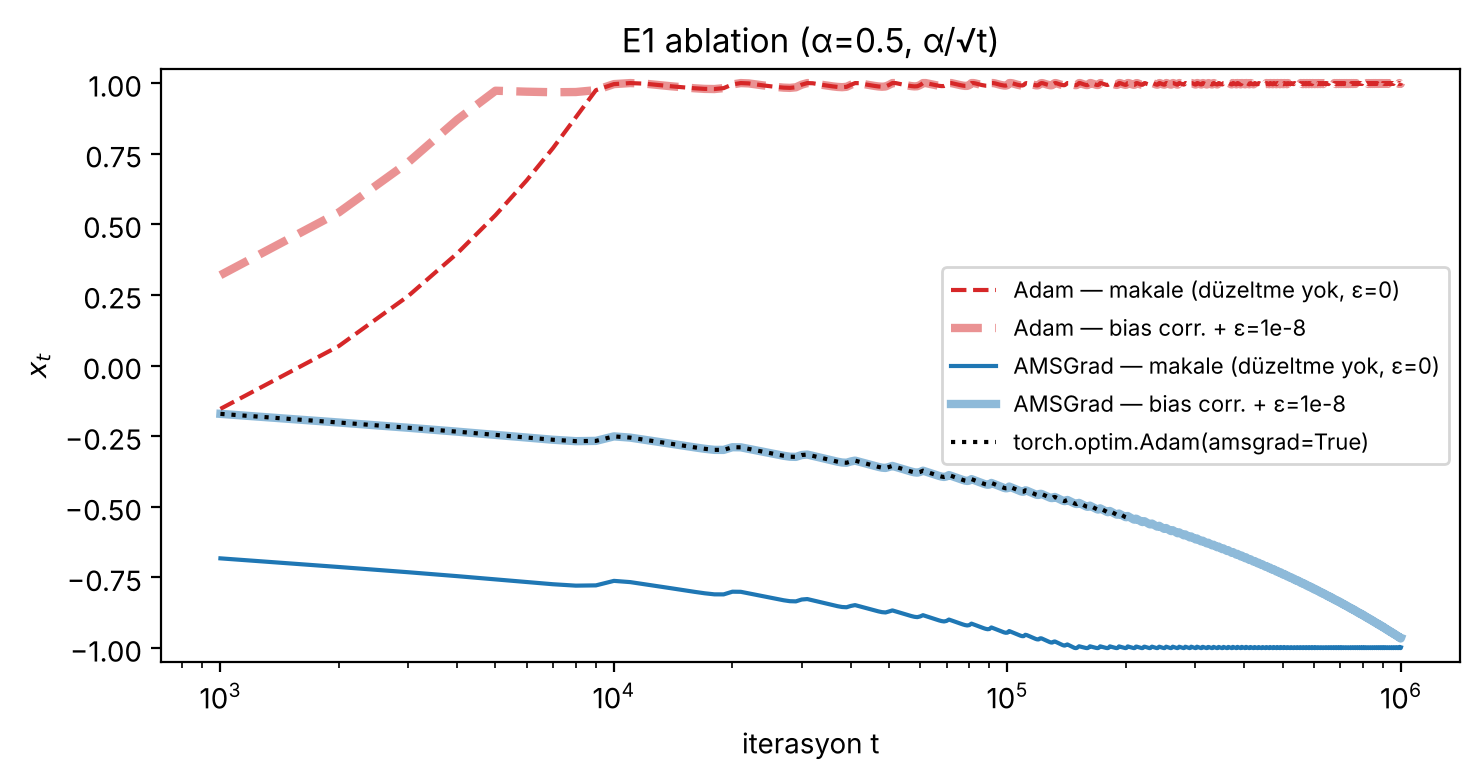

adam     son x: makale = +1.0000 | bias corr. + ε = +1.0000
amsgrad  son x: makale = -0.9973 | bias corr. + ε = -0.9640
torch.optim.Adam(amsgrad=True), t = 200,000: x = -0.536718 | bizim bias corr. sürümü: -0.536718


In [6]:
T_AB = 50_000 if QUICK else 1_000_000
a_sel = float(best[(best.optimizer == "amsgrad") & (best.schedule == "sqrt")]["lr"].iloc[0])
cfg_ab = pd.DataFrame([dict(optimizer=o, lr=a_sel, schedule="sqrt", beta1=0.9, beta2=0.99, seed=0)
                       for o in ("adam", "amsgrad")])
out_paper = simulate(cfg_ab, T_AB, online_grad, -1.0, log_every=1000, verbose=False)
out_bc = simulate(cfg_ab, T_AB, online_grad, -1.0, log_every=1000, verbose=False, bias_correction=True, eps=1e-8)

T_TORCH = 20_000 if QUICK else 200_000
p = torch.nn.Parameter(torch.tensor([1.0], dtype=torch.float64))
opt = torch.optim.Adam([p], lr=a_sel, betas=(0.9, 0.99), eps=1e-8, amsgrad=True)
tx, ty = [], []
for t in range(1, T_TORCH + 1):
    opt.param_groups[0]["lr"] = a_sel / math.sqrt(t)
    p.grad = torch.tensor([online_grad(t)], dtype=torch.float64); opt.step()
    with torch.no_grad():
        p.clamp_(-1, 1)
    if t % 1000 == 0:
        tx.append(t); ty.append(p.item())

fig, ax = plt.subplots(figsize=(7.5, 4))
for i, o in enumerate(("adam", "amsgrad")):
    ax.plot(out_paper["steps"], out_paper["x"][:, i], **style(o, label=f"{STYLE[o]['label']} — makale (düzeltme yok, ε=0)"))
    ax.plot(out_bc["steps"], out_bc["x"][:, i], **style(o, label=f"{STYLE[o]['label']} — bias corr. + ε=1e-8", alpha=0.5, lw=3))
ax.plot(tx, ty, "k:", lw=1.5, label="torch.optim.Adam(amsgrad=True)")
ax.set(xscale="log", xlabel="iterasyon t", ylabel="$x_t$", ylim=(-1.05, 1.05), title=f"E1 ablation (α={a_sel}, α/√t)")
ax.legend(fontsize=8); fig.tight_layout(); save_fig(fig, "e1_ablation", FIG); plt.show()

for i, o in enumerate(("adam", "amsgrad")):
    print(f"{o:8s} son x: makale = {out_paper['x_final'][i]:+.4f} | bias corr. + ε = {out_bc['x_final'][i]:+.4f}")
k = T_TORCH // 1000 - 1
print(f"torch.optim.Adam(amsgrad=True), t = {T_TORCH:,}: x = {ty[-1]:+.6f} | bizim bias corr. sürümü: {out_bc['x'][k, 1]:+.6f}")

## 5. Sonuç notları (rapor / slayt 6)
- Adam'ın $R_t/t$ değeri $20/101 \approx 0.198$'e oturuyorsa Adam sürekli $x=+1$'de demektir.
- α ve takvim seçimi AMSGrad'ın $-1$'e **ne kadar hızlı** gittiğini belirliyor (grid tablosu); sabit α'da büyük α ile AMSGrad da takılabiliyor → "Sapmalar"da tartış.
- Ablation: yön değişmiyor; bias correction + ε yalnızca hızı etkiliyorsa bunu iki cümleyle yaz.